# Case File 03: The Exhibit Wall
**Objective 3 · Data visualization with Matplotlib and Seaborn**

**The case.** Global CO₂ emissions: who emits the most, who emits the most per person, and is economic growth still tied to emissions?
One chart per question, each built to make a single point.

**The witness.** [Our World in Data CO₂ dataset](https://github.com/owid/co2-data), a country-by-year panel.
It is openly licensed and loadable by URL. This notebook reads the local copy in `data/raw/` and falls back to the URL if it is missing.

**Design rules I'm holding myself to:** titles state the finding, one message per chart, no chart junk,
and colour used for meaning rather than decoration.

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

LOCAL = Path("../data/raw/owid-co2-data.csv")
URL = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"
df = pd.read_csv(LOCAL if LOCAL.exists() else URL)
print(df.shape, "| years", df["year"].min(), "to", df["year"].max())

# Rows with no ISO code are regions/aggregates ("World", "Europe", ...), so exclude them
countries = df[df["iso_code"].notna() & (df["iso_code"] != "OWID_WRL")].copy()
countries["gdp_per_capita"] = countries["gdp"] / countries["population"]

sns.set_theme(style="whitegrid", context="talk")
print(f"{countries['country'].nunique()} countries after removing aggregates")

(50411, 79) | years 1750 to 2024
218 countries after removing aggregates


## Exhibit A: who is converging, and who isn't?
Per-person emissions for six large economies since 1960.

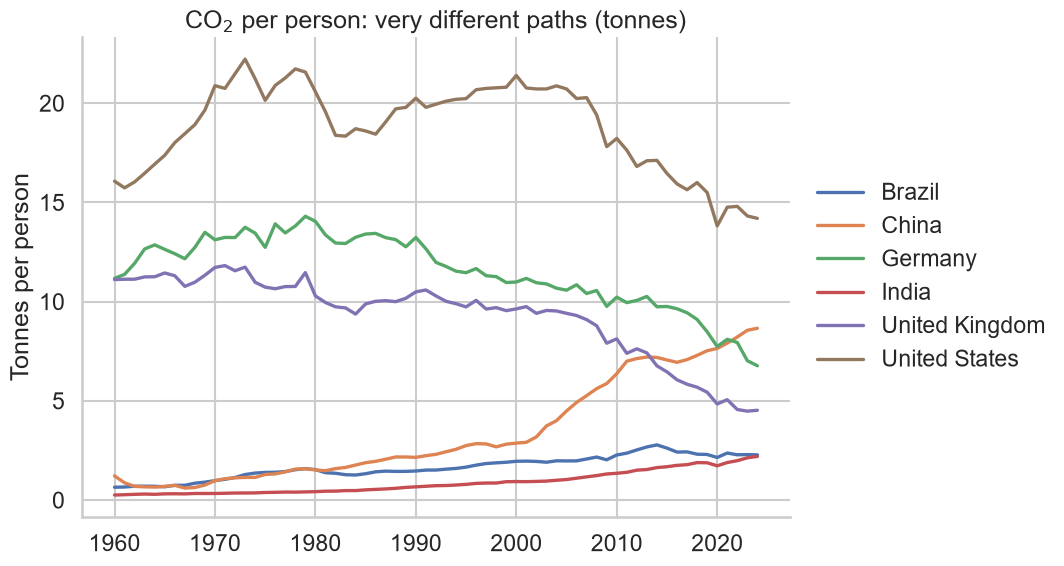

,country,year,co2_per_capita
48007,United States,2024,14.20
9933,China,2024,8.66
18319,Germany,2024,6.77
47782,United Kingdom,2024,4.53
7212,Brazil,2024,2.28
21762,India,2024,2.20


In [7]:
focus = ["India", "China", "United States", "Germany", "Brazil", "United Kingdom"]
a = countries[countries["country"].isin(focus) & (countries["year"] >= 1960)]

fig, ax = plt.subplots(figsize=(11, 6))
sns.lineplot(data=a, x="year", y="co2_per_capita", hue="country", linewidth=2.4, ax=ax)
ax.set(title="CO$_2$ per person: very different paths (tonnes)", xlabel="", ylabel="Tonnes per person")
ax.legend(title="", frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))   # outside, so it never covers a line
sns.despine()
plt.tight_layout()
plt.savefig(FIG / "A_co2_per_capita.png", dpi=200, bbox_inches="tight")
plt.show()

# The numbers behind the picture
latest = a.dropna(subset=["co2_per_capita"]).sort_values("year").groupby("country").tail(1)
latest[["country", "year", "co2_per_capita"]].sort_values("co2_per_capita", ascending=False).round(2)

## Exhibit B: does wealth predict emissions?
One year, log-log axes, bubble area proportional to population.

164 countries with complete data in 2021


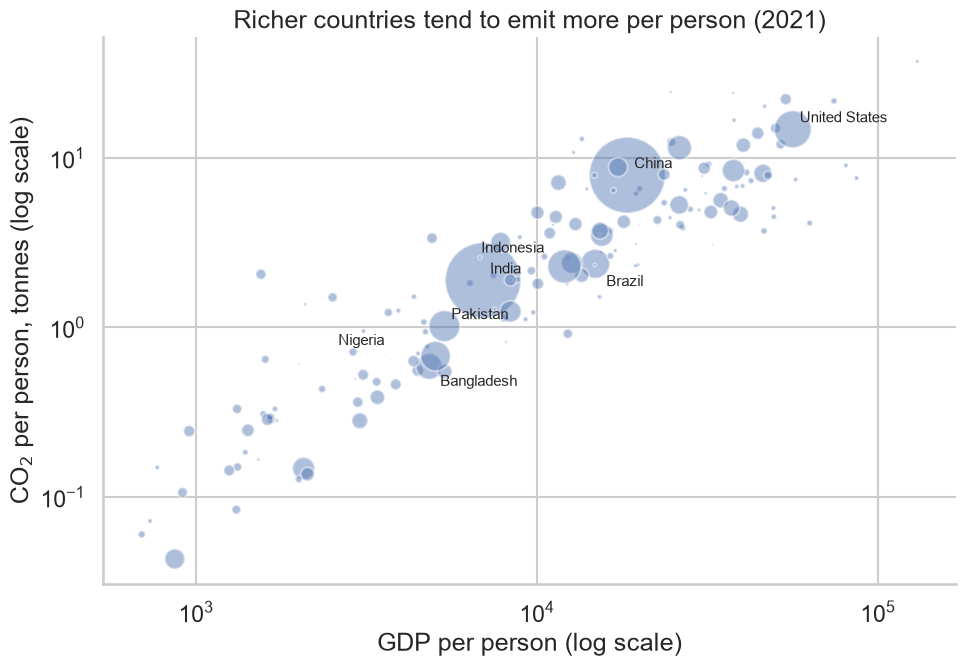

Correlation of log GDP per person with log CO2 per person: r = 0.91


In [8]:
YEAR = 2021                                   # a recent year with solid GDP coverage
b = countries[countries["year"] == YEAR].dropna(subset=["gdp_per_capita", "co2_per_capita", "population"])
print(f"{len(b)} countries with complete data in {YEAR}")

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(b["gdp_per_capita"], b["co2_per_capita"],
           s=b["population"] / b["population"].max() * 3000,    # bubble area ∝ population
           alpha=0.45, edgecolor="white")
ax.set(xscale="log", yscale="log",
       title=f"Richer countries tend to emit more per person ({YEAR})",
       xlabel="GDP per person (log scale)", ylabel="CO$_2$ per person, tonnes (log scale)")

# Label only the biggest populations so the chart stays readable
nudge = {"Brazil": (8, -16), "Indonesia": (-60, 10), "Nigeria": (-70, 8), "Bangladesh": (8, -14)}   # avoid label collisions
for _, r in b.nlargest(8, "population").iterrows():
    ax.annotate(r["country"], (r["gdp_per_capita"], r["co2_per_capita"]),
                xytext=nudge.get(r["country"], (5, 5)), textcoords="offset points", fontsize=11)
sns.despine()
plt.tight_layout()
plt.savefig(FIG / "B_gdp_vs_co2.png", dpi=200)
plt.show()

# How strong is the relationship on the log scale?
r = np.corrcoef(np.log(b["gdp_per_capita"]), np.log(b["co2_per_capita"]))[0, 1]
print(f"Correlation of log GDP per person with log CO2 per person: r = {r:.2f}")

## Exhibit C: who emitted, and when?
Mean annual CO₂ by decade for the 12 largest cumulative emitters since 1950.

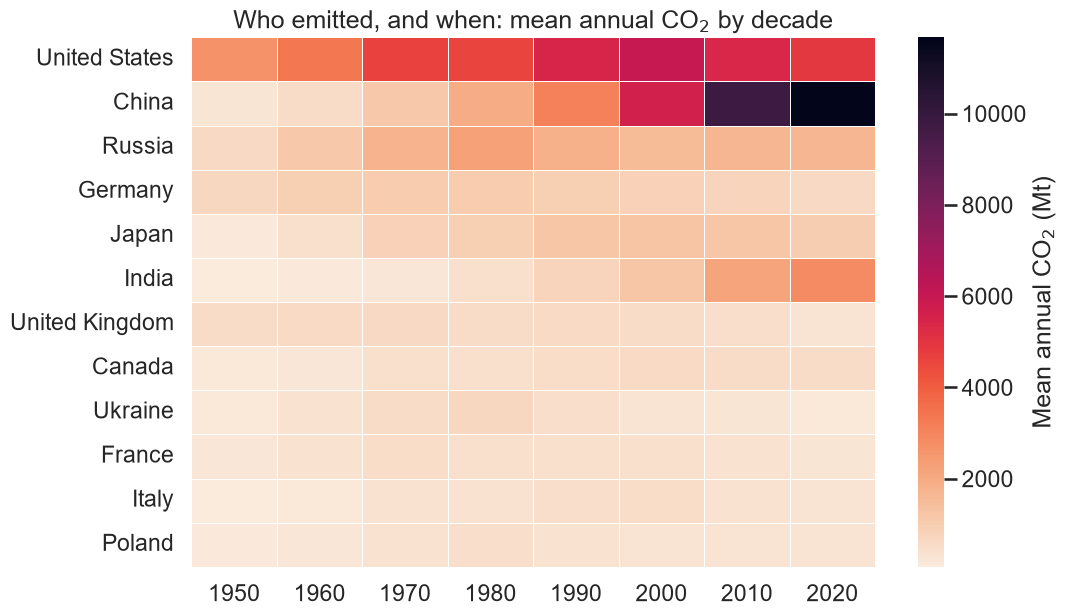

decade,1950,1960,1970,1980,1990,2000,2010,2020
country,,,,,,,,
United States,2682,3372,4626,4595,5427,5969,5395,4918
China,251,536,1149,1936,3111,5623,9848,11671
Russia,615,1123,1778,2259,1807,1560,1663,1699
Germany,676,933,1059,1037,959,873,792,632
Japan,151,401,884,934,1205,1258,1219,1015
India,78,147,228,396,752,1221,2173,2837
United Kingdom,548,604,629,561,580,559,434,320
Canada,171,245,391,430,491,569,565,538
Ukraine,195,356,563,701,457,309,260,169


In [9]:
c = countries[countries["year"] >= 1950].copy()
c["decade"] = (c["year"] // 10) * 10
top = c.groupby("country")["co2"].sum().nlargest(12).index
pivot = (c[c["country"].isin(top)]
         .groupby(["country", "decade"])["co2"].mean()
         .unstack().loc[top])

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.heatmap(pivot, cmap="rocket_r", linewidths=0.4, cbar_kws={"label": "Mean annual CO$_2$ (Mt)"}, ax=ax)
ax.set(title="Who emitted, and when: mean annual CO$_2$ by decade", xlabel="", ylabel="")
plt.tight_layout()
plt.savefig(FIG / "C_emissions_heatmap.png", dpi=200)
plt.show()

pivot.round(0).astype(int)

## What the charts show (numbers from the outputs above)

- **A:** In the latest year (2024) per-person emissions were about 14.2 t in the United States, 8.7 t in China, 6.8 t in Germany, 4.5 t in the UK, 2.3 t in Brazil and 2.2 t in India. China's line passed Germany's around 2020, while the US, Germany and the UK have all been trending down for years.
- **B:** In 2021, across 164 countries with complete data, log GDP per person and log CO₂ per person correlate at r = 0.91. Wealth is a strong predictor of emissions per person, with the United States at the high end and large low-income countries at the low end.
- **C:** China's mean annual emissions grew from about 251 Mt in the 1950s to about 11,671 Mt in the 2020s, while the US peaked in the 2000s (about 5,969 Mt) and has fallen since. Germany, the UK, France and Ukraine have all fallen from earlier peaks.

## What I'd say about these charts
1. **A:** one line per country, titled with the finding. Check the table under it for the latest values.
2. **B:** use medians and ranks, not just the trend line. The log-log scale is what makes the relationship readable.
3. **C:** the heatmap is for *when*, the line chart is for *per person*. Combining them would make a worse chart.

*Limits: CO₂ here is territorial (produced inside each country's borders), so it does not count emissions embedded in imported goods.*